In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
from multiprocessing import Pool
from functools import partial

Loading in the data for all logg values

In [2]:
def get_chisq(dirs_list, plot_savepath):
    # Looping through each folder to extract the abundances and spectra
    results_list = []
    for path in dirs_list:
        spec_path = path + "ra_1639-2632_s419/Mg_I/synth_specs/"
        spec_files = [spec_path + f for f in os.listdir(spec_path) if f.endswith('_spec.csv')]
        
        # Extracting the spectra and abundances
        for spec in spec_files:
            
            # Getting the logg and abundance from the filename
            abund = float(os.path.basename(spec).split('_')[0])
            logg = float(path.split('/')[-2].split('_')[-1])
            print(f"Running logg {logg:.2f}, [Mg/Fe] = {abund:.2f}")
            
            # Loading in the spectra
            spec_df = pd.read_csv(spec)
            synth_wave = spec_df['synth_wave'].values
            synth_flux = spec_df['synth_flux'].values
            obs_wave = spec_df['obs_wave'].values
            obs_flux = spec_df['obs_flux'].values
            obs_flux_err = spec_df['obs_flux_err'].values
            # display(spec_df)
            
            # Masking out the region we want to caclulate chisquares from
            mask_region = (5182, 5185)
            mask_obs = (obs_wave >= mask_region[0]) & (obs_wave <= mask_region[1])
            mask_synth = (synth_wave >= mask_region[0]) & (synth_wave <= mask_region[1])
            
            # Calculating chisquare in the masked region
            chisq_obs = np.sum((obs_flux[mask_obs] - synth_flux[mask_obs])**2 / obs_flux_err[mask_obs]**2)
            chisq_red_obs = chisq_obs / len(obs_flux[mask_obs])
            
            # Storing results into dictionary
            result_dict = {
                'logg': logg,
                'mgfe': abund,
                'chisq_obs': chisq_obs,
                'chisq_red_obs': chisq_red_obs}
            results_list.append(result_dict)

            # Plotting the spectra
            plt.figure(figsize=(10, 6))
            plt.title(f'logg = {logg}, [Mg/Fe] = {abund}\nReduced Chisqr = {chisq_red_obs:.2f}')
            plt.plot(obs_wave, obs_flux, label='Observed', color='black')
            plt.errorbar(obs_wave, obs_flux, yerr=obs_flux_err, fmt='o', markersize=2, color='grey', alpha=0.5)
            plt.plot(synth_wave, synth_flux, label='Synthetic', color='chocolate') # label=f'[{el_}/Fe] = {synth_abund}]\nChisqr = {chisq_obs:.2f}'
            
            ymin, ymax = plt.gca().get_ylim()        
            plt.fill_between(obs_wave[mask_obs], y1=ymin, y2=ymax, color="grey", alpha=0.5)

            plt.xlabel('Wavelength (Å)')
            plt.ylabel('Normalised Flux')
            plt.legend()
            plt.tight_layout()
            plt.savefig(plot_savepath + f'logg_{logg}_mgfe_{abund}_spec.png')
            plt.close()
    
    # Converting results to dataframe
    results_df = pd.DataFrame(results_list)
    return results_df
        

# Getting the folders organised by logg values (from +1.0 to +4.5 dex)
data_path = "/data/misfit/benlowe/xshooter/p115/korg_data/test/ra1639_mg5183_tests/synth_spec/"
plot_savepath = "/data/misfit/benlowe/xshooter/p115/korg_data/test/ra1639_mg5183_tests/plots/"
data_folders = [data_path + f + '/' for f in os.listdir(data_path) if os.path.isdir(os.path.join(data_path, f))]

# Running the chisq calculation with parallel processing
num_cores = 10
data_split = np.array_split(data_folders, num_cores)  
run_partial = partial(get_chisq, 
                      plot_savepath=plot_savepath)

with Pool(processes=num_cores) as pool:  
    all_dfs = pool.map(run_partial, data_split)
    
# Combining all dataframes
final_df = pd.concat(all_dfs, ignore_index=True)

Running logg 2.20, [Mg/Fe] = -0.50Running logg 1.40, [Mg/Fe] = -0.50Running logg 1.80, [Mg/Fe] = -0.50Running logg 1.00, [Mg/Fe] = -0.50Running logg 3.00, [Mg/Fe] = -0.50Running logg 2.60, [Mg/Fe] = -0.50Running logg 3.40, [Mg/Fe] = -0.50Running logg 4.00, [Mg/Fe] = -0.50Running logg 3.70, [Mg/Fe] = -0.50Running logg 4.30, [Mg/Fe] = -0.50









Running logg 1.40, [Mg/Fe] = -0.40
Running logg 3.40, [Mg/Fe] = -0.40
Running logg 4.00, [Mg/Fe] = -0.40
Running logg 2.60, [Mg/Fe] = -0.40
Running logg 1.80, [Mg/Fe] = -0.40
Running logg 4.30, [Mg/Fe] = -0.40
Running logg 3.70, [Mg/Fe] = -0.40
Running logg 3.00, [Mg/Fe] = -0.40
Running logg 2.20, [Mg/Fe] = -0.40
Running logg 1.00, [Mg/Fe] = -0.40
Running logg 1.40, [Mg/Fe] = -0.30
Running logg 2.60, [Mg/Fe] = -0.30
Running logg 3.40, [Mg/Fe] = -0.30
Running logg 4.30, [Mg/Fe] = -0.30
Running logg 4.00, [Mg/Fe] = -0.30
Running logg 3.00, [Mg/Fe] = -0.30
Running logg 1.00, [Mg/Fe] = -0.30
Running logg 3.70, [Mg/Fe] = -0.30
Running logg 1.80, [

Making a 2D histogram of the chisquares

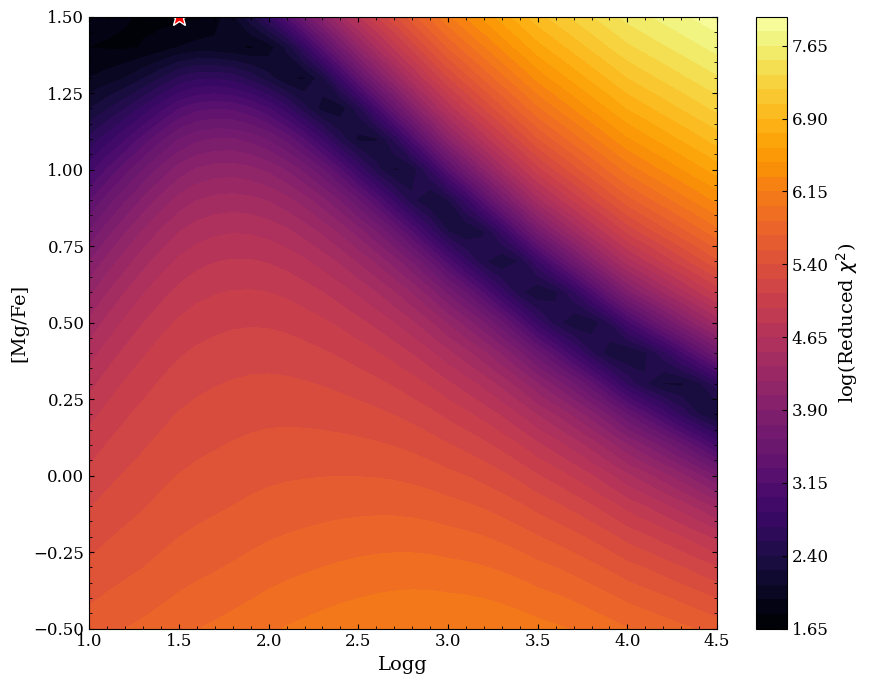

In [4]:
# Pivoting the dataframe into a matrix for contour plotting
chisq_matrix = final_df.pivot(index='logg', columns='mgfe', values='chisq_red_obs')

# Getting the grid arrays for contour plotting
logg_vals = chisq_matrix.index.values
mgfe_vals = chisq_matrix.columns.values
logg_plot, mgfe_plot = np.meshgrid(logg_vals, mgfe_vals)
chisq_vals = np.log(chisq_matrix.values.T)

# Identifying the minimum chisq value and corresponding parameters
min_chisq = final_df['chisq_red_obs'].min()
best_row = final_df.loc[final_df['chisq_red_obs'].idxmin()]
best_logg = best_row['logg']
best_mg = best_row['mgfe']

# Plotting
plt.figure(figsize=(9, 7))
cp = plt.contourf(logg_plot, mgfe_plot, chisq_vals, levels=50, cmap='inferno')
cbar = plt.colorbar(cp)
cbar.set_label(r'log(Reduced $\chi^2$)')

# levels_conf = [min_chisq + 2.30, min_chisq + 6.18]
# cp_lines = plt.contour(logg_plot, mgfe_plot, chisq_vals, levels=levels_conf, colors='white', linestyles=['dashed', 'dotted'])
# plt.clabel(cp_lines, fmt={levels_conf[0]: r'1$\sigma$', levels_conf[1]: r'2$\sigma$'}, inline=True, fontsize=10)

# C. Mark the Best Fit
plt.plot(best_logg, best_mg, '*', color='red', markersize=15, markeredgecolor='white', label='Best Fit')

plt.xlabel('Logg')
plt.ylabel('[Mg/Fe]')
plt.tight_layout()
plt.savefig(plot_savepath + 'chisq_contour_ra1639_mg5183.png', dpi=300)

In [41]:
chisq_vals

array([[ 277.61576423,  250.99555209,  227.90660871,  207.44726845,
         188.48923638,  170.22933832,  152.10842193,  133.90189811,
         115.62808302,   97.52491209,   80.03907158,   63.72123514,
          49.12772169,   36.69489825,   26.63775402,   18.91470285,
          13.28184834,    9.41277665,    7.0349644 ,    6.03804097,
           6.54289373],
       [ 288.95324623,  261.86216058,  238.67909474,  218.44151556,
         200.00752851,  182.50971413,  165.25606859,  147.82577426,
         130.07699125,  112.08842009,   94.15816276,   76.76454765,
          60.4965218 ,   45.94604565,   33.5812815 ,   23.64562199,
          16.12823216,   10.82785633,    7.48884284,    5.95751461,
           6.31409442],
       [ 298.80392966,  271.22036462,  247.91416459,  227.84316265,
         209.94108933,  193.17971122,  176.79520966,  160.25221915,
         143.2423831 ,  125.70054875,  107.7700732 ,   89.80693909,
          72.35043376,   56.04816049,   41.54351129,   29.34368646,
